In [152]:
import scipy.io.wavfile as wav
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import copy
from numpy.fft import fft, fftfreq, ifft
from scipy.fft import fftshift

In [153]:
class signal_data: # Class to store signal data
    def __init__(self, filename):
        self.filename = filename
        self.rate, self.data = wav.read(filename)
        self.increment = 1 / self.rate
        self.length = len(self.data)
        self.duration = self.length / self.rate
        self.time = np.arange(0, self.length) / self.rate
        self.freq_max = self.rate / 2
        self.resolution_freq = self.rate / self.length

class delta_signal: # Class to store delta signal data
    def __init__(self, length):
        self.length = length
        self.data = np.zeros(length)
        self.data[0] = 1

def IIR_filter(signal_data, alpha, beta, delay=1):
   
    filtred_signal = np.zeros(signal_data.length)
    for n in range(signal_data.length):
        if n < delay:
            filtred_signal[n] = alpha * signal_data.data[n]
        else:
            filtred_signal[n] = alpha * signal_data.data[n] + beta * filtred_signal[n - delay]

    return filtred_signal

Sampling Rate: 44100 Hz
Signal Length: 237568 samples
Signal Duration: 5.39 seconds


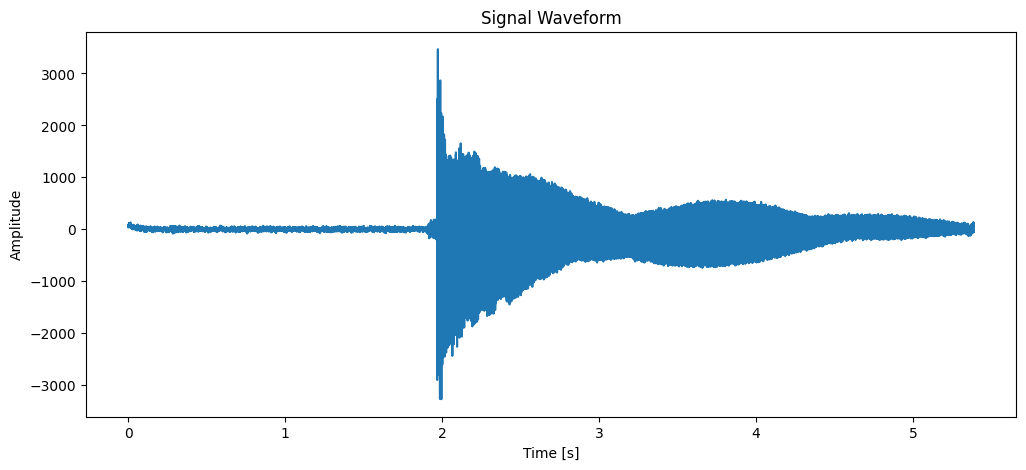

In [154]:
audio_signal = signal_data('data/string_1.wav')
plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=audio_signal.data)
plt.title('Signal Waveform')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
# relevant information about the signal
print(f"Sampling Rate: {audio_signal.rate} Hz")
print(f"Signal Length: {audio_signal.length} samples")
print(f"Signal Duration: {audio_signal.duration:.2f} seconds")

Sampling Rate: 44100 Hz
Signal Length: 237568 samples
Signal Duration: 5.39 seconds


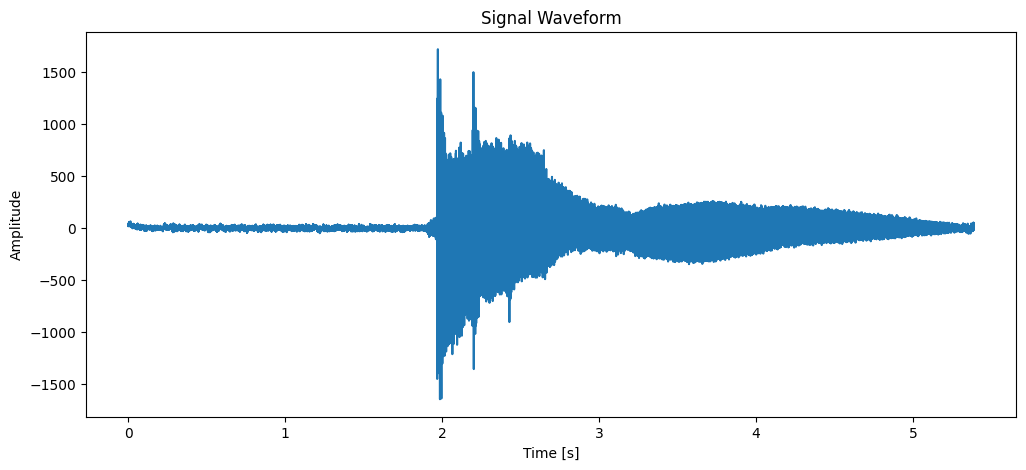

In [155]:
filtred_signal_data = IIR_filter(audio_signal, alpha=0.5, beta=0.5, delay=10000)
plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=filtred_signal_data)
plt.title('Signal Waveform')
plt.xlabel('Time [s]')
plt.ylabel('Amplitude')
# relevant information about the signal
print(f"Sampling Rate: {audio_signal.rate} Hz")
print(f"Signal Length: {audio_signal.length} samples")
print(f"Signal Duration: {audio_signal.duration:.2f} seconds")

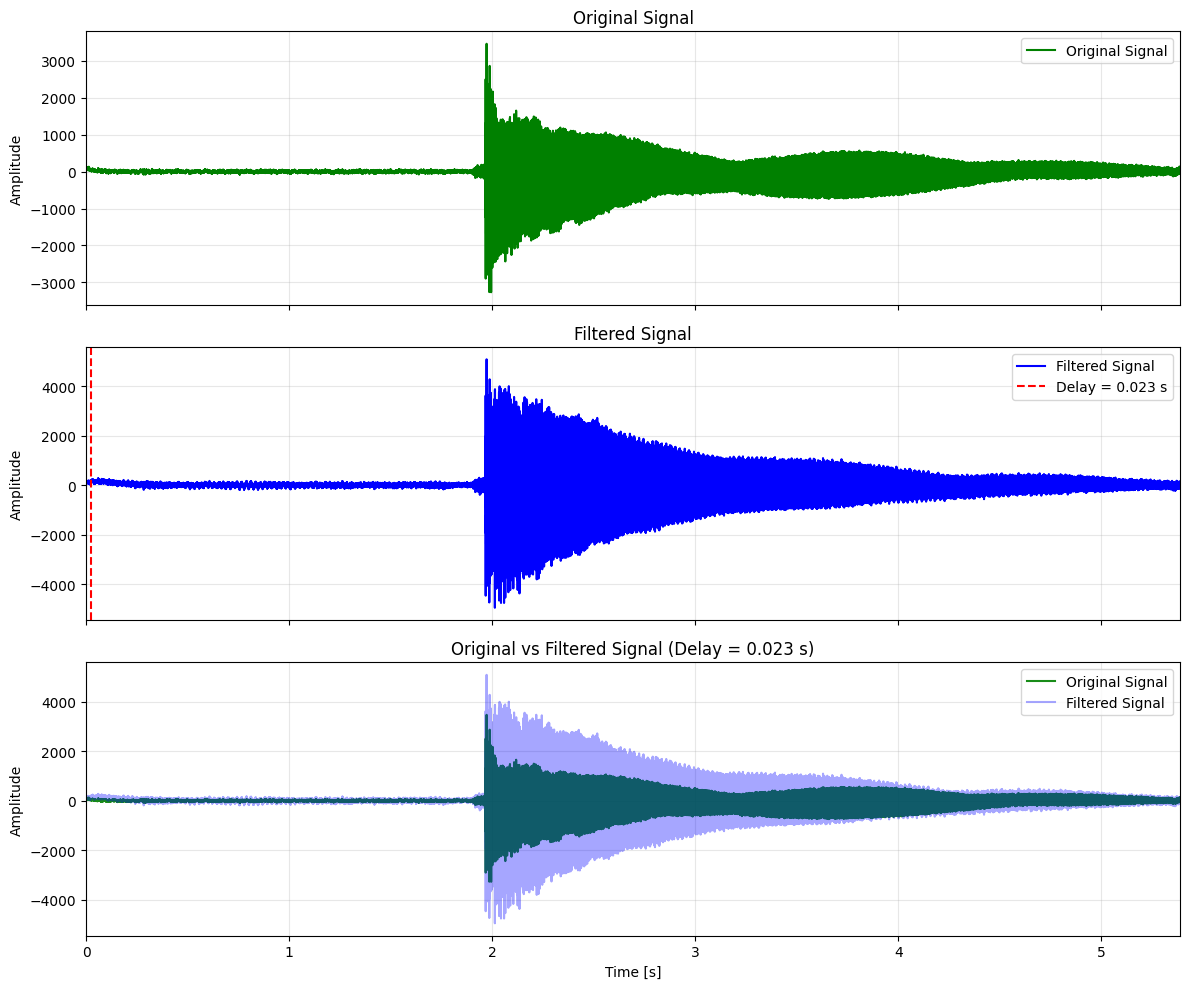

In [156]:
# Apply IIR filter
delay_samples = 1000  # Delay in samples
alpha_value = 1.5  # Feedback coefficient
beta_value = 0.8  # Feedforward coefficient

filtered_signal_data = IIR_filter(
    audio_signal,
    alpha=alpha_value,
    beta=beta_value,
    delay=delay_samples
)

seconds_delay= delay_samples * audio_signal.increment

fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Plot 0 - Original signal
sns.lineplot(
    x=audio_signal.time,
    y=audio_signal.data,
    ax=axes[0],
    label='Original Signal',
    color='green'
)

axes[0].set_title('Original Signal')
axes[0].set_ylabel('Amplitude')
axes[0].grid(alpha=0.3)
axes[0].legend()


# Plot 1 - Filtered signal
sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    ax=axes[1],
    label='Filtered Signal',
    color='b'
)
axes[1].axvline(
    x=seconds_delay,
    color='red',
    linestyle='--',
    label=f'Delay = {seconds_delay:.3f} s'
)

axes[1].set_title('Filtered Signal')
axes[1].set_ylabel('Amplitude')
axes[1].grid(alpha=0.3)
axes[1].legend()


# Plot 2 - Original + filtered

sns.lineplot(
    x=audio_signal.time,
    y=audio_signal.data,
    ax=axes[2],
    label='Original Signal',
    color='green',
    alpha=0.9
)

sns.lineplot(
    x=audio_signal.time,
    y=filtered_signal_data,
    ax=axes[2],
    label='Filtered Signal',
    color='blue',
    alpha=0.35
)


axes[2].set_title(
    f'Original vs Filtered Signal (Delay = {seconds_delay:.3f} s)'
)

axes[2].set_xlabel('Time [s]')
axes[2].set_ylabel('Amplitude')
axes[2].set_xlim(0, audio_signal.duration)
axes[2].grid(alpha=0.3)
axes[2].legend()

plt.tight_layout()
plt.show()

In [157]:
N = len(audio_signal.data)

delta = delta_signal(N)

impulse_response = IIR_filter(delta, alpha=alpha_value, beta=beta_value, delay=delay_samples)
#efecto apha en posicion 0 
# alpha *beta en posicion delay


Text(0, 0.5, 'Amplitude')

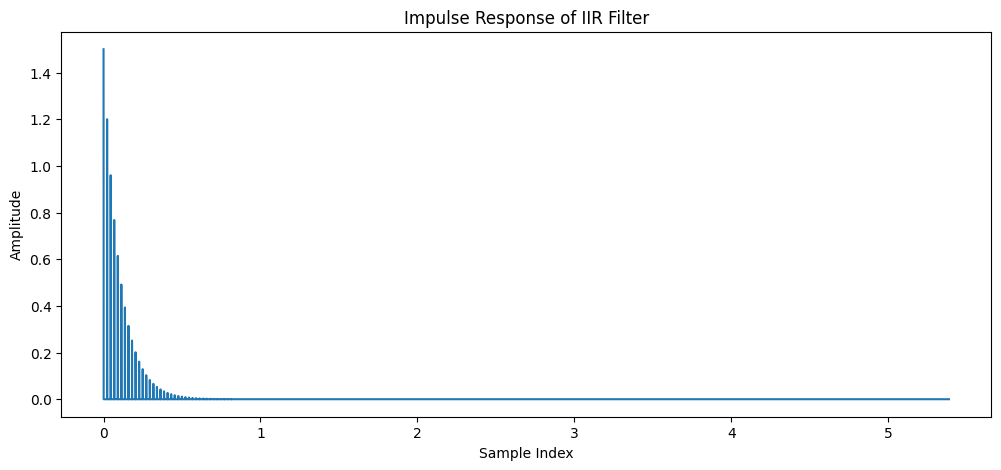

In [158]:
plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time, y=impulse_response)
plt.title('Impulse Response of IIR Filter')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')

Text(0, 0.5, 'Amplitude')

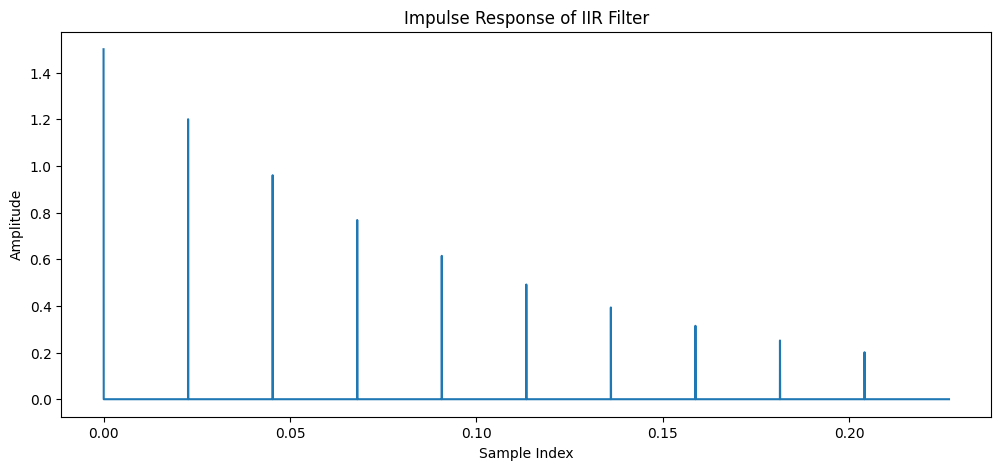

In [159]:
plt.figure(figsize=(12, 5))
sns.lineplot(x=audio_signal.time[0:10000], y=impulse_response[0:10000])
plt.title('Impulse Response of IIR Filter')
plt.xlabel('Sample Index')
plt.ylabel('Amplitude')

Text(0, 0.5, 'Magnitude')

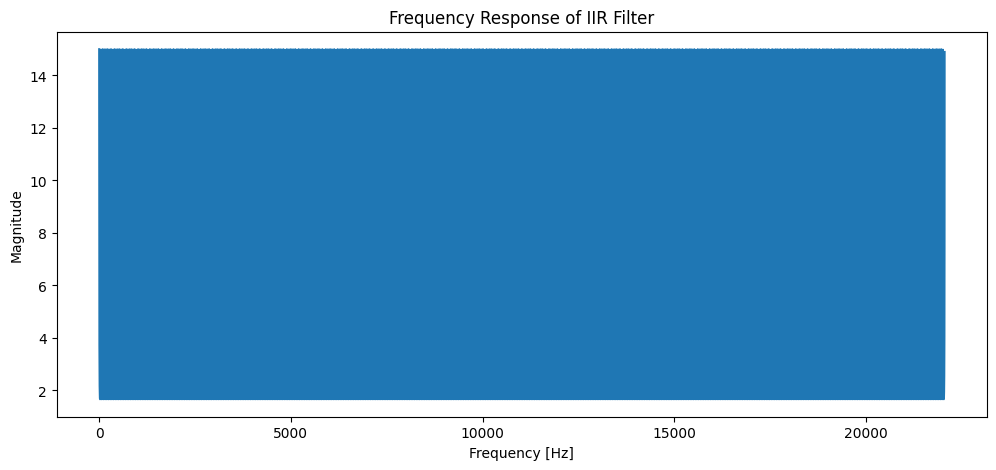

In [160]:
# frequency response of the filter

# 1. Discrete Fourier Transform (DFT)
fft_sig_s1 = fft(impulse_response)
freqs_s1 = fftfreq(len(impulse_response), d=1/audio_signal.rate)

# Centered version (zero in the middle), for a symmetric plot
sig_s1_shift = fftshift(fft_sig_s1)
f_s1_shift = fftshift(freqs_s1)
mag_shift = np.abs(sig_s1_shift)

# One-sided version: positive frequencies only
mitad = len(impulse_response) // 2
f_pos = freqs_s1[:mitad]
mag_pos = 2 * np.abs(fft_sig_s1[:mitad])

# Plot frequency response
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos, y=mag_pos)
plt.title('Frequency Response of IIR Filter')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')


Text(0, 0.5, 'Magnitude')

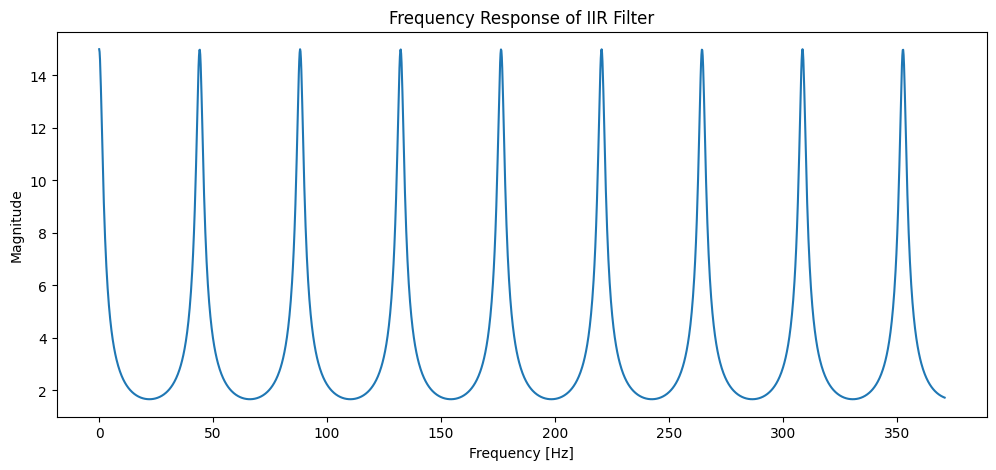

In [161]:
# Plot frequency response
plt.figure(figsize=(12, 5))
sns.lineplot(x=f_pos[0:2000], y=mag_pos[0:2000])
plt.title('Frequency Response of IIR Filter')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')

237568
237568


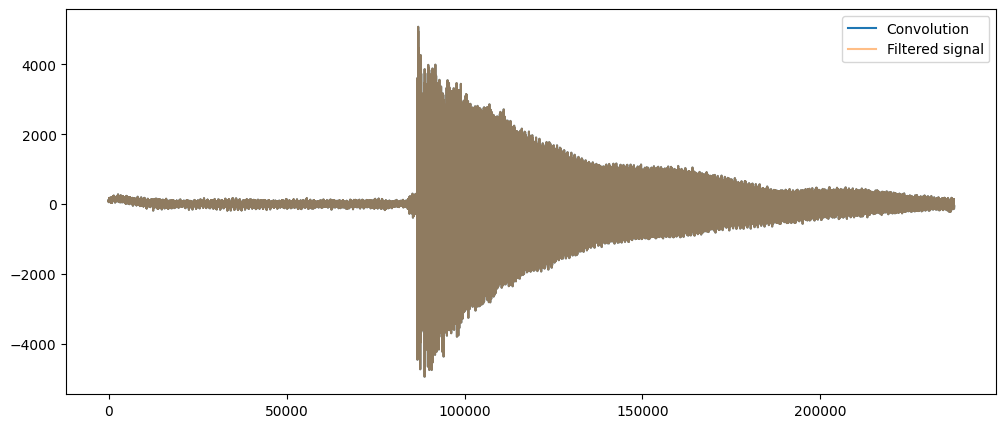

Is the filtered signal equal to the convolution signal? True


In [162]:
from scipy.signal import fftconvolve

# Full convolution
conv_full = fftconvolve(
    audio_signal.data,
    impulse_response,
    mode="full" # we have used full to be able to obtain a linear convolution with the requirement of Lx + Lh - 1
)

# Keep the causal part corresponding to the original signal
conv_signal = conv_full[:len(audio_signal.data)]

print(len(conv_signal))
print(len(filtered_signal_data))

plt.figure(figsize=(12, 5))
plt.plot(conv_signal, label="Convolution")
plt.plot(filtered_signal_data, label="Filtered signal", alpha=0.5)
plt.legend()
plt.show()

print(f'Is the filtered signal equal to the convolution signal? {np.allclose(conv_signal, filtered_signal_data)}')

Length of original signal: 237568
Length of impulse response: 237568
Length required for linear convolution: 475135
Length of padded signal: 475135
Length of padded impulse response: 475135


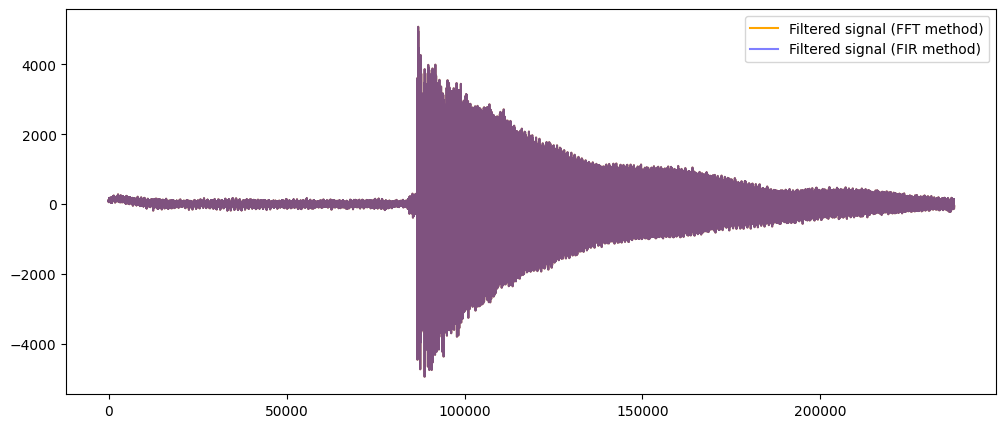

Is the filtered signal equal to the filtered signal using the FFT method? True


In [163]:



print(f"Length of original signal: {len(audio_signal.data)}")
print(f"Length of impulse response: {len(impulse_response)}")

N = 2 * audio_signal.length - 1
print(f"Length required for linear convolution: {N}")

# Amount of zero-padding needed
N_padding = N - len(audio_signal.data)

# Zero-padding
audio_signal_padded = np.pad(
    audio_signal.data,
    (0, N_padding),
    mode='constant'
)

impulse_response_padded = np.pad(
    impulse_response,
    (0, N_padding),
    mode='constant'
)

print(f"Length of padded signal: {len(audio_signal_padded)}")
print(f"Length of padded impulse response: {len(impulse_response_padded)}")

# FFT
audio_signal_fft = fft(audio_signal_padded)
impulse_response_fft = fft(impulse_response_padded)

# Multiplication in frequency domain
audio_signal_filtered_fft = (
    audio_signal_fft * impulse_response_fft
)

# Back to time domain
audio_signal_filtered_fftmethod = np.real(
    ifft(audio_signal_filtered_fft)
)[0:len(audio_signal.data)]  # Keep only the causal part corresponding to the original signal

# Compare
plt.figure(figsize=(12, 5))

plt.plot(
    audio_signal_filtered_fftmethod,
    label="Filtered signal (FFT method)",
    color='orange'
)

plt.plot(
    filtered_signal_data,
    label="Filtered signal (FIR method)",
    alpha=0.5,
    color='blue'
)

plt.legend()
plt.show()

print(f'Is the filtered signal equal to the filtered signal using the FFT method? {np.allclose(audio_signal_filtered_fftmethod, filtered_signal_data)}')